# Problem Set 4 - Comparing Traditional Text Representations and Word Embeddings for Text Classification

Name: **Jessica Mae T. Lanuzo**                | Section: **BSCS 3A**
<hr>

### Dataset used: AG News

Description from Hugging Face:
- AG is a collection of more than 1 million news articles. News articles have been gathered from more than 2000 news sources by ComeToMyHead in more than 1 year of activity. ComeToMyHead is an academic news search engine which has been running since July, 2004. The dataset is provided by the academic comunity for research purposes in data mining (clustering, classification, etc), information retrieval (ranking, search, etc), xml, data compression, data streaming, and any other non-commercial activity. For more information, please refer to the link http://www.di.unipi.it/~gulli/AG_corpus_of_news_articles.html .

Available at: https://huggingface.co/datasets/fancyzhx/ag_news

# Implementation

In [53]:
%pip install pandas nltk
%pip install datasets
%pip install -U scikit-learn
%pip install scipy
%pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## I. Text Preprocessing

### Setting up libraries

In [54]:
import os
import re
import gzip
import pickle
import urllib.request

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from datasets import load_dataset

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/jesslanuzo/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

### Importing the dataset

In [55]:
# pd.set_option('display.max_colwidth', None)

In [56]:
# Import dataset
dataset = load_dataset("fancyzhx/ag_news")

# Convert to pandas DataFrame
df_train = dataset['train'].to_pandas()
df_test = dataset['test'].to_pandas()

In [57]:
# Preview first 5 instances of training set
df_train.head()

,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [58]:
# Preview first 5 instances of testing set
df_test.head()

,text,label
0,Fears for T N pension after talks Unions repre...,2
1,The Race is On: Second Private Team Sets Launc...,3
2,Ky. Company Wins Grant to Study Peptides (AP) ...,3
3,Prediction Unit Helps Forecast Wildfires (AP) ...,3
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,3


### Text Cleaning and Tokenization

In [59]:
stop_words = set(stopwords.words("english"))

def clean_and_tokenize(text):
    text = text.lower()                     # normalize case
    text = re.sub(r"[^a-z0-9\s]", "", text) # remove punctuation, special characters
    tokens = word_tokenize(text)            # tokenize into words
    tokens = [t for t in tokens if t not in stop_words] # remove stopwords
    return tokens

df_train['tokens'] = df_train['text'].apply(clean_and_tokenize)
df_test['tokens'] = df_test['text'].apply(clean_and_tokenize)

In [60]:
# Preview first 5 instances of training set
df_train.head()

,text,label,tokens
0,Wall St. Bears Claw Back Into the Black (Reute...,2,"[wall, st, bears, claw, back, black, reuters, ..."
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,"[carlyle, looks, toward, commercial, aerospace..."
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,"[oil, economy, cloud, stocks, outlook, reuters..."
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,"[iraq, halts, oil, exports, main, southern, pi..."
4,"Oil prices soar to all-time record, posing new...",2,"[oil, prices, soar, alltime, record, posing, n..."


In [61]:
# Preview first 5 instances of testing set
df_test.head()

,text,label,tokens
0,Fears for T N pension after talks Unions repre...,2,"[fears, n, pension, talks, unions, representin..."
1,The Race is On: Second Private Team Sets Launc...,3,"[race, second, private, team, sets, launch, da..."
2,Ky. Company Wins Grant to Study Peptides (AP) ...,3,"[ky, company, wins, grant, study, peptides, ap..."
3,Prediction Unit Helps Forecast Wildfires (AP) ...,3,"[prediction, unit, helps, forecast, wildfires,..."
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,3,"[calif, aims, limit, farmrelated, smog, ap, ap..."


## II. Text Representation

### TF-IDF Vectorization

In [62]:
# Flatten sentences back into documents
train_docs = df_train['tokens'].apply(lambda tok_list: " ".join(tok_list))
test_docs = df_test['tokens'].apply(lambda tok_list: " ".join(tok_list))

tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(train_docs)
X_test = tfidf.transform(test_docs)

y_train = df_train['label']
y_test = df_test['label']

print(X_train.shape)
print(X_test.shape)

(120000, 5000)
(7600, 5000)


In [63]:
# persist TF-IDF baseline artifacts

# filenames
PICKLE_TFIDF = "tfidf_vectorizer.pkl"
NPZ_X_TRAIN   = "X_train_tfidf.npz"
NPZ_X_TEST    = "X_test_tfidf.npz"
TXT_TRAIN_DOC = "train_docs.txt"
TXT_TEST_DOC  = "test_docs.txt"
NP_Y_TRAIN    = "y_train.npy"
NP_Y_TEST     = "y_test.npy"

# save vectorizer
with open(PICKLE_TFIDF, "wb") as f:
    pickle.dump(tfidf, f)

# save sparse matrices
sp.save_npz(NPZ_X_TRAIN, X_train)
sp.save_npz(NPZ_X_TEST, X_test)

# save flattened documents (one doc per line) for reproducibility
train_docs.to_csv(TXT_TRAIN_DOC, index=False, header=False)
test_docs.to_csv(TXT_TEST_DOC, index=False, header=False)

# save labels
np.save(NP_Y_TRAIN, y_train.values)
np.save(NP_Y_TEST, y_test.values)

print("Saved:")
print(f" - TF-IDF vectorizer -> {PICKLE_TFIDF}")
print(f" - X_train (sparse) -> {NPZ_X_TRAIN}")
print(f" - X_test  (sparse) -> {NPZ_X_TEST}")
print(f" - train_docs -> {TXT_TRAIN_DOC}")
print(f" - test_docs  -> {TXT_TEST_DOC}")
print(f" - y_train -> {NP_Y_TRAIN}")
print(f" - y_test  -> {NP_Y_TEST}")

Saved:
 - TF-IDF vectorizer -> tfidf_vectorizer.pkl
 - X_train (sparse) -> X_train_tfidf.npz
 - X_test  (sparse) -> X_test_tfidf.npz
 - train_docs -> train_docs.txt
 - test_docs  -> test_docs.txt
 - y_train -> y_train.npy
 - y_test  -> y_test.npy


### FastText Word Embedding

In [64]:
# 1) Download pretrained vectors if not present (cc.en.300.vec.gz)
ft_gz = "cc.en.300.vec.gz"
ft_url = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.en.300.vec.gz"

if not os.path.exists(ft_gz):
    print("Downloading pretrained FastText...")
    urllib.request.urlretrieve(ft_url, ft_gz)

# 2) Build dataset vocabulary so we only load vectors we actually need
vocab = set()
for toks in df_train['tokens']:
    vocab.update(toks)
for toks in df_test['tokens']:
    vocab.update(toks)

print(f"Unique tokens in dataset: {len(vocab):,}")

# 3) Load only required vectors from the .vec.gz file (no gensim needed)
embeddings = {}
dim = None
with gzip.open(ft_gz, "rt", encoding="utf-8", newline="\n", errors="ignore") as f:
    header = f.readline().strip().split()
    if len(header) >= 2 and header[0].isdigit() and header[1].isdigit():
        dim = int(header[1])
    else:
        # Fallback if file has no header
        parts = header
        word = parts[0]
        vec = np.asarray(parts[1:], dtype=np.float32)
        dim = len(vec)
        if word in vocab:
            embeddings[word] = vec

    for line in f:
        parts = line.rstrip().split(" ")
        if len(parts) < 2:
            continue
        word = parts[0]
        if word not in vocab:
            continue
        try:
            vec = np.asarray(parts[1:], dtype=np.float32)
            if dim is None:
                dim = len(vec)
            if len(vec) == dim:
                embeddings[word] = vec
        except ValueError:
            continue

print(f"Loaded vectors for {len(embeddings):,} tokens (dim={dim}).")

# 4) Helper: plain average of known token vectors (returns zero vector if none found)
def doc_vec_avg(tokens):
    vecs = [embeddings[t] for t in tokens if t in embeddings]
    if not vecs:
        return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0)

# 5) Compute document vectors
print("Computing plain-averaged document vectors for train and test...")
X_train_ft_plain = np.vstack(df_train['tokens'].apply(doc_vec_avg).values)
X_test_ft_plain  = np.vstack(df_test['tokens'].apply(doc_vec_avg).values)

# 6) Save results for later model training
np.save("X_train_ft_plain.npy", X_train_ft_plain)
np.save("X_test_ft_plain.npy", X_test_ft_plain)

print("Done.")
print("Shapes -> X_train_ft_plain:", X_train_ft_plain.shape, "X_test_ft_plain:", X_test_ft_plain.shape)
print("Saved: X_train_ft_plain.npy, X_test_ft_plain.npy")

Unique tokens in dataset: 105,133
Loaded vectors for 57,237 tokens (dim=300).
Computing plain-averaged document vectors for train and test...
Done.
Shapes -> X_train_ft_plain: (120000, 300) X_test_ft_plain: (7600, 300)
Saved: X_train_ft_plain.npy, X_test_ft_plain.npy


### TF-IDF Weighted FastText Word Embedding

In [65]:
# Fit TF-IDF on training split only for weighting
tfidf_weighted = TfidfVectorizer(max_features=5000)
X_train_weighting = tfidf_weighted.fit_transform(train_docs)
X_test_weighting = tfidf_weighted.transform(test_docs)
feature_names_weighted = np.array(tfidf_weighted.get_feature_names_out())

PICKLE_FT_WEIGHTED_TFIDF = "tfidf_fasttext_weighted_vectorizer.pkl"
with open(PICKLE_FT_WEIGHTED_TFIDF, "wb") as f:
    pickle.dump(tfidf_weighted, f)

def doc_vec_weighted(tfidf_row):
    weighted_sum = np.zeros(dim, dtype=np.float32)
    weight_total = 0.0
    for idx, weight in zip(tfidf_row.indices, tfidf_row.data):
        word = feature_names_weighted[idx]
        vec = embeddings.get(word)
        if vec is not None:
            weighted_sum += vec * weight
            weight_total += weight
    if weight_total == 0:
        return np.zeros(dim, dtype=np.float32)
    return weighted_sum / weight_total

print("Computing TF-IDF weighted document vectors for train and test...")
X_train_ft_weighted = np.vstack([doc_vec_weighted(row) for row in X_train_weighting.tocsr()])
X_test_ft_weighted  = np.vstack([doc_vec_weighted(row) for row in X_test_weighting.tocsr()])

np.save("X_train_ft_weighted.npy", X_train_ft_weighted)
np.save("X_test_ft_weighted.npy", X_test_ft_weighted)

print("Done.")
print("Shapes -> X_train_ft_weighted:", X_train_ft_weighted.shape, "X_test_ft_weighted:", X_test_ft_weighted.shape)
print("Saved: X_train_ft_weighted.npy, X_test_ft_weighted.npy")
print(f"Saved TF-IDF weighting vectorizer -> {PICKLE_FT_WEIGHTED_TFIDF}")

Computing TF-IDF weighted document vectors for train and test...
Done.
Shapes -> X_train_ft_weighted: (120000, 300) X_test_ft_weighted: (7600, 300)
Saved: X_train_ft_weighted.npy, X_test_ft_weighted.npy
Saved TF-IDF weighting vectorizer -> tfidf_fasttext_weighted_vectorizer.pkl


## III. Model Training and Evaluation

In [66]:
def evaluate_representation(name, X_train_rep, X_test_rep):
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_rep, y_train)
    y_pred = model.predict(X_test_rep)
    print(f"{name} Results")
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall": recall_score(y_test, y_pred, average="macro"),
        "F1-Score": f1_score(y_test, y_pred, average="macro")
    }

results = []
results.append(evaluate_representation("TF-IDF", X_train, X_test))
results.append(evaluate_representation("FastText Plain Average", X_train_ft_plain, X_test_ft_plain))
results.append(evaluate_representation("FastText TF-IDF Weighted", X_train_ft_weighted, X_test_ft_weighted))

df_results = pd.DataFrame(results)
df_results

TF-IDF Results
              precision    recall  f1-score   support

           0       0.92      0.90      0.91      1900
           1       0.95      0.98      0.96      1900
           2       0.87      0.87      0.87      1900
           3       0.87      0.87      0.87      1900

    accuracy                           0.90      7600
   macro avg       0.90      0.90      0.90      7600
weighted avg       0.90      0.90      0.90      7600

[[1705   62   78   55]
 [  23 1854   10   13]
 [  62   20 1644  174]
 [  66   23  154 1657]]
FastText Plain Average Results
              precision    recall  f1-score   support

           0       0.90      0.89      0.89      1900
           1       0.94      0.96      0.95      1900
           2       0.84      0.84      0.84      1900
           3       0.86      0.85      0.85      1900

    accuracy                           0.88      7600
   macro avg       0.88      0.88      0.88      7600
weighted avg       0.88      0.88      0.88   

,Model,Accuracy,Precision,Recall,F1-Score
0,TF-IDF,0.902632,0.902324,0.902632,0.902387
1,FastText Plain Average,0.883158,0.882869,0.883158,0.882968
2,FastText TF-IDF Weighted,0.874868,0.874376,0.874868,0.874573


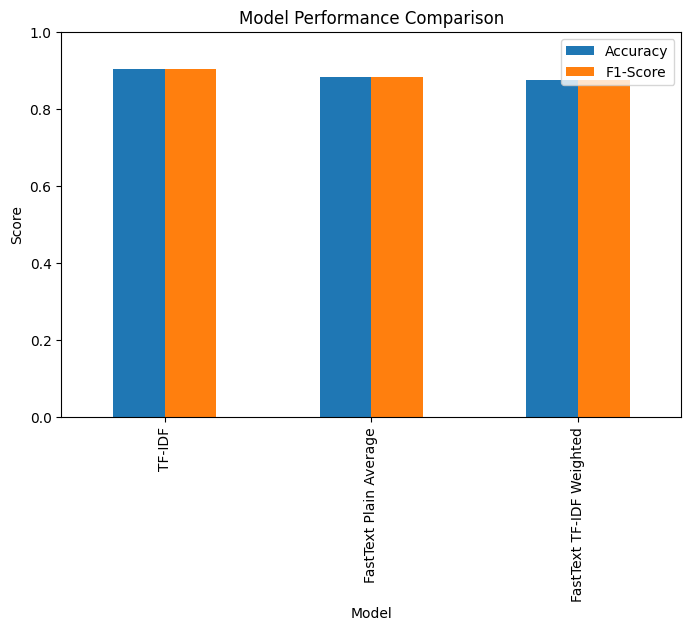

In [67]:
df_results.set_index("Model")[["Accuracy", "F1-Score"]].plot(kind="bar", figsize=(8, 5))
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.show()

#

In [68]:
## Per-Class Performance: Where Does Each Representation Win?

from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

class_names = {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Science/Technology'}

for name, X_train_rep, X_test_rep in [
    ("TF-IDF", X_train, X_test),
    ("FastText Plain Average", X_train_ft_plain, X_test_ft_plain),
    ("FastText TF-IDF Weighted", X_train_ft_weighted, X_test_ft_weighted)
]:
    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_rep, y_train)
    y_pred = model.predict(X_test_rep)
    print(f"\n{'='*60}")
    print(f"{name} - Per-Class Accuracy")
    print(f"{'='*60}")
    print(classification_report(y_test, y_pred, target_names=[class_names[i] for i in range(4)], digits=4))


TF-IDF - Per-Class Accuracy
                    precision    recall  f1-score   support

             World     0.9186    0.8974    0.9079      1900
            Sports     0.9464    0.9758    0.9609      1900
          Business     0.8717    0.8653    0.8685      1900
Science/Technology     0.8726    0.8721    0.8723      1900

          accuracy                         0.9026      7600
         macro avg     0.9023    0.9026    0.9024      7600
      weighted avg     0.9023    0.9026    0.9024      7600


FastText Plain Average - Per-Class Accuracy
                    precision    recall  f1-score   support

             World     0.9012    0.8884    0.8948      1900
            Sports     0.9392    0.9600    0.9495      1900
          Business     0.8351    0.8368    0.8360      1900
Science/Technology     0.8559    0.8474    0.8516      1900

          accuracy                         0.8832      7600
         macro avg     0.8829    0.8832    0.8830      7600
      weighted avg   

In [69]:
## Representation Efficiency: Sparsity vs. Density Tradeoff

print("\n" + "="*70)
print("REPRESENTATION EFFICIENCY & INFORMATION DENSITY")
print("="*70)

# TF-IDF sparsity calculation
sparsity_tfidf = 1 - (X_train.nnz / (X_train.shape[0] * X_train.shape[1]))
tfidf_memory = (X_train.nnz * 16) / 1e6  # Estimate: 8 bytes per value + 8 for index

print(f"\nTF-IDF (Sparse Representation):")
print(f"  • Dimensions:      {X_train.shape[1]} features")
print(f"  • Sparsity:        {sparsity_tfidf:.1%} (only important words stored)")
print(f"  • Effective Memory: ~{tfidf_memory:.1f} MB (only non-zero values)")
print(f"  • Information:     Lexical features with explicit term importance (TF-IDF weights)")

# FastText density
fasttext_memory_plain = (X_train_ft_plain.size * 8) / 1e6

print(f"\nFastText (Dense Representation):")
print(f"  • Dimensions:      {X_train_ft_plain.shape[1]} features (fixed)")
print(f"  • Sparsity:        0% (all dimensions always computed)")
print(f"  • Memory:          ~{fasttext_memory_plain:.1f} MB (all 300 dims stored)")
print(f"  • Information:     Semantic similarity (context-independent word vectors)")


REPRESENTATION EFFICIENCY & INFORMATION DENSITY

TF-IDF (Sparse Representation):
  • Dimensions:      5000 features
  • Sparsity:        99.6% (only important words stored)
  • Effective Memory: ~34.0 MB (only non-zero values)
  • Information:     Lexical features with explicit term importance (TF-IDF weights)

FastText (Dense Representation):
  • Dimensions:      300 features (fixed)
  • Sparsity:        0% (all dimensions always computed)
  • Memory:          ~288.0 MB (all 300 dims stored)
  • Information:     Semantic similarity (context-independent word vectors)


In [70]:
## Top Discriminative Features: What Does TF-IDF Actually Learn?

feature_names = tfidf.get_feature_names_out()

# For each class, get top words by average TF-IDF score
print("\n" + "="*70)
print("TOP 15 DISCRIMINATIVE WORDS PER NEWS CATEGORY (by avg TF-IDF weight)")
print("="*70)

for class_idx in range(4):
    class_name = class_names[class_idx]
    # Get indices of documents in this class
    class_mask = (y_train.values == class_idx)
    
    # Average TF-IDF weights for this class
    class_docs_tfidf = X_train[class_mask]
    if class_docs_tfidf.shape[0] > 0:
        avg_tfidf = np.asarray(class_docs_tfidf.mean(axis=0)).flatten()
        top_indices = np.argsort(avg_tfidf)[-15:][::-1]
        top_words = feature_names[top_indices]
        top_weights = avg_tfidf[top_indices]
        
        print(f"\n{class_name}:")
        print(f"  {', '.join(top_words)}")
        print(f"  (avg TF-IDF range: {top_weights[0]:.4f} - {top_weights[-1]:.4f})")


TOP 15 DISCRIMINATIVE WORDS PER NEWS CATEGORY (by avg TF-IDF weight)

World:
  iraq, said, ap, us, reuters, president, 39s, afp, minister, killed, two, un, iraqi, people, bush
  (avg TF-IDF range: 0.0250 - 0.0122)

Sports:
  39s, ap, game, win, team, season, first, cup, night, league, victory, new, coach, world, last
  (avg TF-IDF range: 0.0284 - 0.0127)

Business:
  us, oil, 39s, reuters, said, new, prices, inc, company, percent, profit, stocks, sales, york, corp
  (avg TF-IDF range: 0.0295 - 0.0138)

Science/Technology:
  microsoft, new, software, 39s, internet, ap, space, reuters, music, computer, search, company, technology, ibm, web
  (avg TF-IDF range: 0.0242 - 0.0111)
